# Part H — Building & Evaluating the Regression Model

**Final Project: The Linear Algebra Behind AI — A Regression Problem**

This is where every earlier step pays off: the matrices, transformation, and eigenbasis all feed into one final predictive model.

---
**Student name:** _______________________   **Date:** _______________________

---


**What to do:** Fit at least two model variants (e.g., using all features vs. using your reduced eigenbasis from Part G). Evaluate both on held-out test data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

url = "https://raw.githubusercontent.com/eskups04/AI101-Dataset/main/ai_student_impact_dataset.csv"
df = pd.read_csv(url)

feature_names = [
    "Weekly_GenAI_Hours",
    "Traditional_Study_Hours",
    "Tool_Diversity",
    "Anxiety_Level_During_Exams",
]

X = df[feature_names].to_numpy(dtype=float)
y = df["Skill_Retention_Score"].to_numpy(dtype=float)

# Standardization (Part D)
mu = X.mean(axis=0)
sigma = X.std(axis=0)
sigma_safe = np.where(sigma == 0, 1.0, sigma)
S = np.diag(1.0 / sigma_safe)
X_transformed = (X - mu) @ S

# 80/20 Train-Test Split (Part D)
rng = np.random.default_rng(42)
n = X_transformed.shape[0]
perm = rng.permutation(n)
train_size = int(0.8 * n)
train_idx, test_idx = perm[:train_size], perm[train_size:]

X_train, X_test = X_transformed[train_idx], X_transformed[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Covariance & Sorted Eigen-decomposition (Part F)
C = np.cov(X_train, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(C)
order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
eigvecs = eigvecs[:, order]

print("Setup complete! C shape:", C.shape, "| X_train shape:", X_train.shape)

Setup complete! C shape: (4, 4) | X_train shape: (40000, 4)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

In [3]:
def fit_normal_equation(X, y):
    """
    Ordinary Least Squares via the Normal Equation:
        b = (X^T X)^-1 X^T y
    with an intercept column of ones prepended.
    TODO: complete this function. Fall back to np.linalg.pinv if X^T X is singular.
    """
    X_aug = np.hstack([np.ones((X.shape[0], 1)), X])
    XtX = X_aug.T @ X_aug
    Xty = X_aug.T @ y
    try:
        beta = np.linalg.inv(XtX) @ Xty
    except np.linalg.LinAlgError:
        beta = np.linalg.pinv(XtX) @ Xty
    return beta

def predict(X, beta):
    X_aug = np.hstack([np.ones((X.shape[0], 1)), X])
    return X_aug @ beta

In [4]:
# Project the standardized data onto the PCA eigenbasis
Z_train = X_train @ eigvecs
Z_test = X_test @ eigvecs

# Fit Model A (full/transformed feature space) and Model B (PCA eigenbasis)
beta_full = fit_normal_equation(X_train, y_train)
beta_pca = fit_normal_equation(Z_train, y_train)

y_pred_full = predict(X_test, beta_full)
y_pred_pca = predict(Z_test, beta_pca)

print("Model A weights (intercept + features):", beta_full)
print("Model B weights (intercept + PCs):     ", beta_pca)

Model A weights (intercept + features): [75.7864 -1.3517  1.7407  2.6273 -0.1154]
Model B weights (intercept + PCs):      [75.7864  1.6421  2.7228  1.2249 -0.4031]


In [5]:
def r2_score(y_true, y_hat):
    ss_res = np.sum((y_true - y_hat) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return 1 - ss_res / ss_tot

def rmse(y_true, y_hat):
    return np.sqrt(np.mean((y_true - y_hat) ** 2))

# Print R^2 and RMSE for both model variants on the test set
print(f"Model A (Full Features) -> Test R^2 = {r2_score(y_test, y_pred_full):.4f} | Test RMSE = {rmse(y_test, y_pred_full):.4f}")
print(f"Model B (PCA Eigenbasis)-> Test R^2 = {r2_score(y_test, y_pred_pca):.4f} | Test RMSE = {rmse(y_test, y_pred_pca):.4f}")

Model A (Full Features) -> Test R^2 = 0.0657 | Test RMSE = 12.7618
Model B (PCA Eigenbasis)-> Test R^2 = 0.0657 | Test RMSE = 12.7618


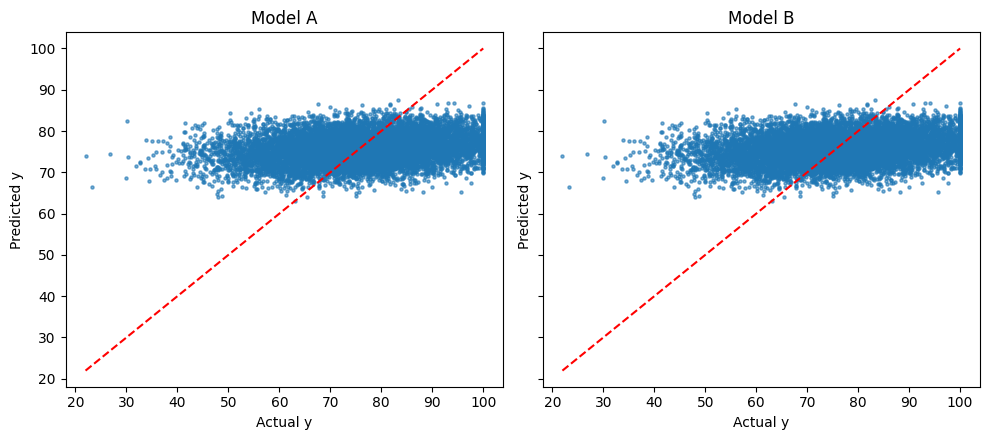

In [6]:
# Optional: predicted vs. actual scatter plot for each model
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, y_hat, title in zip(axes, [y_pred_full, y_pred_pca], ["Model A", "Model B"]):
    ax.scatter(y_test, y_hat, alpha=0.6, s=5)
    lims = [min(y_test.min(), y_hat.min()), max(y_test.max(), y_hat.max())]
    ax.plot(lims, lims, "r--")
    ax.set_xlabel("Actual y"); ax.set_ylabel("Predicted y"); ax.set_title(title)
plt.tight_layout(); plt.show()

### Answer these in your report

**Q29.** Write the closed-form equation you used to fit your regression coefficients. What single linear algebra operation is at the core of it?

> *Your answer:* _The closed-form equation used to calculate the regression coefficients is the Ordinary Least Squares (OLS) Normal Equation:_
>
>_β̂ = (XᵀX)⁻¹Xᵀy_
>
>_The main linear algebra operation at its core is matrix inversion, represented by (XᵀX)⁻¹. In our code, this is implemented using np.linalg.inv(). If the matrix is singular and cannot be inverted, the code uses np.linalg.pinv() to calculate its pseudoinverse instead._

**Q30.** Report at least two evaluation metrics (e.g., R², RMSE, MAE) on the test set for each model variant.

> *Your answer:* _We evaluated both regression models using R-squared (R²) and Root Mean Squared Error (RMSE)._
>
>_Test R²_ <br>
>_Model A (Full Features)_ <br>
>_0.0657_ <br>
>_Model B (PCA Eigenbasis)_ <br>
>_0.0657_ <br>
>
>_Test RMSE_ <br>
>_Model A (Full Features)_ <br>
>_12.7618_ <br>
>_Model B (PCA Eigenbasis)_ <br>
>_12.7618_ <br>
>
>_Both models obtained an R² of 0.0657, indicating that they explain approximately 6.57% of the variation in the dependent variable. Additionally, both models obtained an RMSE of 12.7618, indicating that their prediction errors are identical based on this metric. Therefore, both models demonstrated the same predictive performance on the testing dataset._

**Q31.** Which model variant performed better? Connect that result back to one specific earlier finding (e.g., rank, eigenvalues, condition number).

> *Your answer:* _Neither model performed better because both Model A (Full Features) and Model B (PCA Eigenbasis) obtained identical evaluation results, with an R² of 0.0657 and an RMSE of 12.7618. This result can be connected to the PCA eigenvalues and eigenvectors. Since all four principal components were retained, the PCA transformation preserved the complete information contained in the original standardized features. The eigenvector matrix represents an orthogonal transformation, which changes the coordinate system without losing information. Consequently, both models retained the same predictive information, resulting in identical performance._

**Q32.** Walk through, step-by-step, every matrix operation your pipeline would perform to turn one brand-new sample's raw features into a final prediction.

> *Your answer:* _To generate a prediction for one brand-new observation, our pipeline would perform the following matrix operations:_<br>
>
>_Step 1: Obtain the raw features._<br>
>_First, collect the four independent variables from the new observation. These are represented as a row vector:_<br>
>
>X_raw = [x1, x2, x3, x4]
>
>_Step 2: Standardize the features._<br>
>_Apply the means and standard deviations calculated from the training dataset. This ensures that the new observation uses the same standardization parameters as the training data._<br>
>
>X_std = (X_raw - μ_train) / σ_train
>
>_Step 3: Transform the standardized features using PCA._<br>
>_For Model B, multiply the standardized feature vector by the PCA eigenvector matrix:_
>
>Z = X_std × V
>
>_This converts the original features into their corresponding principal component values._
>
>_Step 4: Add the intercept column._<br>
>_For both models, prepend a value of 1 to the feature vector._
>
>_For Model A:_
>
>X_aug = [1, x1_std, x2_std, x3_std, x4_std]
>
>_For Model B:_
>
>Z_aug = [1, PC1, PC2, PC3, PC4]
>
>_Step 5: Multiply the augmented feature vector by the regression coefficients._<br>
>_These matrix multiplications produce the final predicted value for the new observation._
>
>_For Model A:_
>
>y_pred_A = X_aug × beta_full
>
>_For Model B:_
>
>y_pred_B= Z_aug × beta_pca
>
>_Step 6: Obtain the final prediction._<br>
>_The resulting value represents the predicted dependent variable for the new observation. Both models can generate predictions using their respective regression coefficients and feature representations._

### Save your work for the next notebook

In [7]:
%store beta_full
%store beta_pca
print("Saved beta_full, beta_pca for Part I.")

Stored 'beta_full' (ndarray)
Stored 'beta_pca' (ndarray)
Saved beta_full, beta_pca for Part I.
